In [1]:
print("Hello, Benford's Law!")

Hello, Benford's Law!


In [2]:
!uv add pandas
import pandas as pd

Resolved 37 packages in 291ms                                        
Prepared 3 packages in 345ms                                                 pandas               ------------------------------ 8.97 MiB/10.74 MiB          pandas               ------------------------------ 4.25 MiB/10.74 MiB          
Uninstalled 1 package in 1ms
Installed 3 packages in 19ms                                
 ~ benford==0.1.0 (from file:///Users/ijasenovski/cpp/mmap3/benford)
 + numpy==2.5.4
 + pandas==3.1.0


In [3]:
!uv add matplotlib
import matplotlib.pyplot as plt

Resolved 44 packages in 85ms                                         
Prepared 4 packages in 1.29s                                                 pillow               ------------------------------ 3.14 MiB/4.63 MiB           pillow               ------------------------------ 3.02 MiB/4.63 MiB           pillow               ------------------------------     0 B/4.63 MiB            
Uninstalled 1 package in 0.67ms
Installed 8 packages in 24ms                                
 ~ benford==0.1.0 (from file:///Users/ijasenovski/cpp/mmap3/benford)
 + contourpy==1.4.0
 + cycler==0.12.1
 + fonttools==4.67.0
 + kiwisolver==1.5.1
 + matplotlib==3.11.2
 + pillow==13.0.0
 + pyparsing==3.3.3


In [6]:
import os
import numpy as np

In [9]:
digitos = range(1, 10)
probs_benford = {}
for digito in digitos:
    probs_benford[digito] = np.log10(1 + 1 / digito)
# print(probs_benford)
benford = pd.Series(probs_benford, name="Benford Esperado")
display(benford)

1    0.301030
2    0.176091
3    0.124939
4    0.096910
5    0.079181
6    0.066947
7    0.057992
8    0.051153
9    0.045757
Name: Benford Esperado, dtype: float64

In [10]:
N = 10_000

r = np.random.RandomState(seed=42)
valores = r.lognormal(mean=5.0, sigma=1.5, size=N)
print(valores)

[312.64589665 120.61498716 392.1062336  ...  51.52282504 312.20135852
 390.17005413]


In [13]:
df = pd.DataFrame({"valor": valores})
display(df)

,valor
0,312.645897
1,120.614987
2,392.106234
3,1457.597461
4,104.456419
...,...
9995,1044.875579
9996,7.407423
9997,51.522825
9998,312.201359


In [28]:
# df["valor"].iloc[0]
# abs(df["valor"].iloc[0])
# str(abs(df["valor"].iloc[0]))
# str(abs(df["valor"].iloc[0])).lstrip("0")
# str(abs(df["valor"].iloc[0])).lstrip("0").replace(".", "")
# str(abs(df["valor"].iloc[0])).lstrip("0").replace(".", "")[0]
print(str(abs(df["valor"].iloc[0])).lstrip("0").replace(".", "")[0])
print(str(abs(0.21)).lstrip("0").replace(".", "")[0])
print(str(abs(-0.74)).lstrip("0").replace(".", "")[0])

3
2
7


In [29]:
def primeiro_digito(x: float) -> int:
    return int(str(abs(x)).lstrip("0").replace(".", "")[0])
print(primeiro_digito(-7.5))
print(primeiro_digito(0.63))

7
6


In [31]:
df["primeiro_digito"] = df["valor"].apply(primeiro_digito)
display(df)

,valor,primeiro_digito
0,312.645897,3
1,120.614987,1
2,392.106234,3
3,1457.597461,1
4,104.456419,1
...,...,...
9995,1044.875579,1
9996,7.407423,7
9997,51.522825,5
9998,312.201359,3


In [36]:
# display(df["primeiro_digito"].value_counts(normalize=True))
freq_obs = df["primeiro_digito"].value_counts(normalize=True)
freq_obs.name = "Observado"
display(freq_obs)

primeiro_digito
1    0.3049
2    0.1737
3    0.1256
4    0.0957
5    0.0770
6    0.0681
7    0.0584
8    0.0527
9    0.0439
Name: Observado, dtype: float64

In [47]:
df_final = pd.DataFrame(
    {"Benford (%)": benford * 100,
     "Observado (%)": freq_obs * 100,
     "Diferença (%)": (freq_obs - benford) * 100,
     "Observado": (freq_obs * N),
     "Esperado": (benford * N)
    }
)
display(df_final.round(2))

,Benford (%),Observado (%),Diferença (%),Observado,Esperado
1,30.10,30.49,0.39,3049.0,3010.30
2,17.61,17.37,-0.24,1737.0,1760.91
3,12.49,12.56,0.07,1256.0,1249.39
4,9.69,9.57,-0.12,957.0,969.10
5,7.92,7.70,-0.22,770.0,791.81
6,6.69,6.81,0.12,681.0,669.47
7,5.80,5.84,0.04,584.0,579.92
8,5.12,5.27,0.15,527.0,511.53
9,4.58,4.39,-0.19,439.0,457.57


In [53]:
df_final["Diferença"] = df_final["Esperado"] - df_final["Observado"]
df_final["QQ"] = df_final["Diferença"] ** 2 / df_final["Esperado"]
display(df_final)

,Benford (%),Observado (%),Diferença (%),Observado,Esperado,Diferença,QQ
1,30.103000,30.49,0.387000,3049.0,3010.299957,-38.700043,0.497523
2,17.609126,17.37,-0.239126,1737.0,1760.912591,23.912591,0.324725
3,12.493874,12.56,0.066126,1256.0,1249.387366,-6.612634,0.034999
4,9.691001,9.57,-0.121001,957.0,969.100130,12.100130,0.151082
5,7.918125,7.70,-0.218125,770.0,791.812460,21.812460,0.600879
6,6.694679,6.81,0.115321,681.0,669.467896,-11.532104,0.198649
7,5.799195,5.84,0.040805,584.0,579.919470,-4.080530,0.028712
8,5.115252,5.27,0.154748,527.0,511.525224,-15.474776,0.468146
9,4.575749,4.39,-0.185749,439.0,457.574906,18.574906,0.754034


In [55]:
df_final["QQ"].sum()

np.float64(3.0587490619796593)

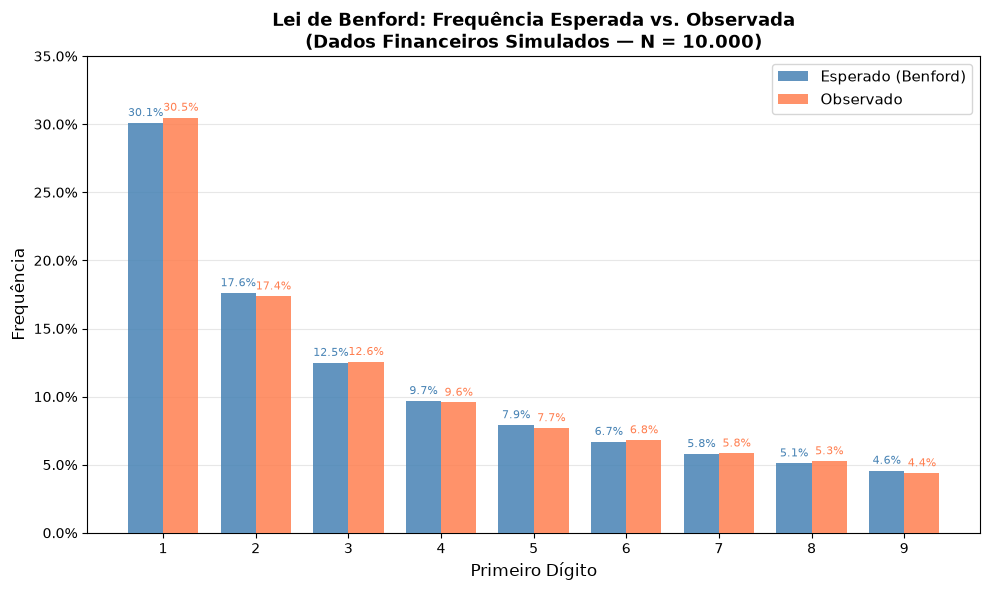

In [58]:
import matplotlib.ticker as mtick

x = np.arange(1, 10)
largura = 0.38

fig, eixo = plt.subplots(figsize=(10, 6))

barras_esp = eixo.bar(x - largura / 2, benford.values * 100, largura,
                      label="Esperado (Benford)", color="steelblue", alpha=0.85, zorder=3)
barras_obs = eixo.bar(x + largura / 2, freq_obs.values * 100, largura,
                      label="Observado", color="coral", alpha=0.85, zorder=3)

# Rótulos sobre as barras
for barra in barras_esp:
    eixo.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.3,
              f"{barra.get_height():.1f}%", ha="center", va="bottom", fontsize=8, color="steelblue")
for barra in barras_obs:
    eixo.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.3,
              f"{barra.get_height():.1f}%", ha="center", va="bottom", fontsize=8, color="coral")

eixo.set_xlabel("Primeiro Dígito", fontsize=12)
eixo.set_ylabel("Frequência", fontsize=12)
eixo.set_title("Lei de Benford: Frequência Esperada vs. Observada\n(Dados Financeiros Simulados — N = 10.000)",
               fontsize=13, fontweight="bold")
eixo.set_xticks(x)
eixo.yaxis.set_major_formatter(mtick.PercentFormatter())
eixo.legend(fontsize=11)
eixo.grid(axis="y", alpha=0.3, zorder=0)
eixo.set_ylim(0, 35)

plt.tight_layout()
plt.show()

In [65]:
print(df_final["Observado"].values)
print(df_final["Esperado"].values.round(0))

[3049. 1737. 1256.  957.  770.  681.  584.  527.  439.]
[3010. 1761. 1249.  969.  792.  669.  580.  512.  458.]


In [67]:
!uv add openpyxl
df_gastos_deputados = pd.read_excel(
    os.path.join("dados", "Ano-2025.xlsx")
)
df_gastos_deputados

Resolved 46 packages in 122ms                                        
Prepared 1 package in 8ms                                                             ⠙ Preparing packages... (0/1)                                                   
Uninstalled 1 package in 0.89ms
Installed 3 packages in 8ms                                 
 ~ benford==0.1.0 (from file:///Users/ijasenovski/cpp/mmap3/benford)
 + et-xmlfile==2.0.0
 + openpyxl==3.1.5


/Users/ijasenovski/cpp/mmap3/benford/.venv/lib/python3.14/site-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,txNomeParlamentar,cpf,ideCadastro,nuCarteiraParlamentar,nuLegislatura,sgUF,sgPartido,codLegislatura,numSubCota,txtDescricao,...,numParcela,txtPassageiro,txtTrecho,numLote,numRessarcimento,datPagamentoRestituicao,vlrRestituicao,nuDeputadoId,ideDocumento,urlDocumento
0,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2115566,NaN,NaN,NaN,2812,7877589,https://www.camara.leg.br/cota-parlamentar/doc...
1,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2123760,NaN,NaN,NaN,2812,7892756,https://www.camara.leg.br/cota-parlamentar/doc...
2,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2131750,NaN,NaN,NaN,2812,7907982,https://www.camara.leg.br/cota-parlamentar/doc...
3,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2139804,NaN,NaN,NaN,2812,7923034,https://www.camara.leg.br/cota-parlamentar/doc...
4,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2150181,NaN,NaN,NaN,2812,7940865,https://www.camara.leg.br/cota-parlamentar/doc...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208329,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,5,DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.,...,0,NaN,NaN,2199991,NaN,NaN,NaN,3803,8034979,https://www.camara.leg.br/cota-parlamentar/doc...
208330,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,13,FORNECIMENTO DE ALIMENTAÇÃO DO PARLAMENTAR,...,0,NaN,NaN,2198808,NaN,NaN,NaN,3803,8032796,https://www.camara.leg.br/cota-parlamentar/not...
208331,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,120,LOCAÇÃO OU FRETAMENTO DE VEÍCULOS AUTOMOTORES,...,0,NaN,NaN,2199423,NaN,NaN,NaN,3803,8033995,https://www.camara.leg.br/cota-parlamentar/not...
208332,Heloísa Helena,3.645032e+10,234788.0,633.0,2023,RJ,REDE,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2206738,NaN,NaN,NaN,3804,8046527,https://www.camara.leg.br/cota-parlamentar/not...


In [ ]:
df_gastos_deputados.info()

<class 'pandas.DataFrame'>
RangeIndex: 208334 entries, 0 to 208333
Data columns (total 32 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   txNomeParlamentar          208334 non-null  str    
 1   cpf                        207397 non-null  float64
 2   ideCadastro                207397 non-null  float64
 3   nuCarteiraParlamentar      207397 non-null  float64
 4   nuLegislatura              208334 non-null  int64  
 5   sgUF                       207397 non-null  str    
 6   sgPartido                  207397 non-null  str    
 7   codLegislatura             208334 non-null  int64  
 8   numSubCota                 208334 non-null  int64  
 9   txtDescricao               208334 non-null  str    
 10  numEspecificacaoSubCota    208334 non-null  int64  
 11  txtDescricaoEspecificacao  71474 non-null   str    
 12  txtFornecedor              208334 non-null  str    
 13  txtCNPJCPF                 171127 non-nu

In [71]:
digitos = list(range(1, 10))
benford_esperado = {d: np.log10(1 + 1 / d) for d in digitos}
pct_esperado = [benford_esperado[d] * 100 for d in digitos]

def distribuicao_benford(serie):
    serie = serie.dropna()
    serie = serie[serie > 0]
    digitos = serie.apply(primeiro_digito).dropna().astype(int)
    total = len(digitos)
    contagem = digitos.value_counts()
    pct_obs = [contagem.get(d, 0) / total * 100 for d in range(1, 10)]
    return total, pct_obs

def primeiro_digito(valor):
    try:
        return int(str(valor).lstrip("0.")[0])
    except (ValueError, IndexError):
        return None

In [ ]:
!uv add python-dotenv
from dotenv import load_dotenv

Resolved 47 packages in 101ms                                        
Prepared 2 packages in 35ms                                                  python-dotenv        ------------------------------ 22.72 KiB/22.72 KiB         
Uninstalled 1 package in 0.90ms
Installed 2 packages in 1ms file:///Users/ijasenovski/cpp/mm
 ~ benford==0.1.0 (from file:///Users/ijasenovski/cpp/mmap3/benford)
 + python-dotenv==1.2.4


In [77]:
load_dotenv("db.env", override=True)
DB_HOST = os.getenv("DB_HOST")
DB_USER = os.getenv("DB_USER")
DB_PASS = os.getenv("DB_PASS")
DB_NAME = os.getenv("DB_NAME")
DB_PORT = os.getenv("DB_PORT")

display(DB_HOST, DB_USER, DB_NAME, DB_PORT)

'localhost'

'postgres'

'db_benford'

'5432'

In [ ]:
!uv add sqlalchemy psycopg2-binary
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

Resolved 49 packages in 190ms                                        
Prepared 2 packages in 96ms                                                  sqlalchemy           ------------------------------ 318.79 KiB/2.36 MiB         
Uninstalled 1 package in 1ms
Installed 3 packages in 4ms.13                              
 ~ benford==0.1.0 (from file:///Users/ijasenovski/cpp/mmap3/benford)
 + psycopg2-binary==2.9.13
 + sqlalchemy==2.1.6


In [80]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
url = URL.create(
    drivername="postgresql+psycopg2",
    username=DB_USER,
    password=DB_PASS,
    host=DB_HOST,
    port=DB_PORT,
    database=DB_NAME)

engine = create_engine(url, connect_args={"connect_timeout": 10})
con = engine.connect()

In [81]:
SQL = """
CREATE TABLE IF NOT EXISTS tb_gastos_deputados (
    id                          BIGINT GENERATED ALWAYS AS IDENTITY PRIMARY KEY,
    txnomeparlamentar           TEXT,
    cpf                         BIGINT,            -- float64 no df por conter nulos (NaN)
    idecadastro                 BIGINT,            -- float64 no df por conter nulos (NaN)
    nucarteiraparlamentar       BIGINT,            -- float64 no df por conter nulos (NaN)
    nulegislatura               INTEGER,
    sguf                        VARCHAR(2),
    sgpartido                   VARCHAR(20),
    codlegislatura              INTEGER,
    numsubcota                  INTEGER,
    txtdescricao                TEXT,
    numespecificacaosubcota     INTEGER,
    txtdescricaoespecificacao   TEXT,
    txtfornecedor               TEXT,
    txtcnpjcpf                  VARCHAR(20),
    txtnumero                   TEXT,
    indtipodocumento            INTEGER,
    datemissao                  TIMESTAMP,         -- string ISO no df; PostgreSQL converte automaticamente
    vlrdocumento                NUMERIC(15, 2),
    vlrglosa                    NUMERIC(15, 2),
    vlrliquido                  NUMERIC(15, 2),
    nummes                      SMALLINT,
    numano                      SMALLINT,
    numparcela                  INTEGER,
    txtpassageiro               TEXT,
    txttrecho                   TEXT,
    numlote                     INTEGER,
    numressarcimento            BIGINT,            -- float64 no df por conter nulos (NaN)
    datpagamentorestituicao     TIMESTAMP,
    vlrrestituicao              NUMERIC(15, 2),
    nudeputadoid                INTEGER,
    idedocumento                BIGINT,
    urldocumento                TEXT
);
CREATE INDEX IF NOT EXISTS idx_gastos_partido_ano ON tb_gastos_deputados (sgpartido, numano);
CREATE INDEX IF NOT EXISTS idx_gastos_vlrliquido  ON tb_gastos_deputados (vlrliquido);
"""
con.execute(text(SQL))
con.commit()

In [82]:
query = """
SELECT table_name, table_schema, table_type
FROM information_schema.tables 
WHERE table_schema = 'public'"""

result = con.execute(text(query))
tabelas = list(result)
display(tabelas)

[('tb_gastos_deputados', 'public', 'BASE TABLE')]

In [83]:
df_gastos_deputados.rename(columns={col: col.lower() 
                            for col in df_gastos_deputados.columns}, 
                                inplace=True)
df_gastos_deputados

/var/folders/cy/5qrtd5ts60347djj0yj4_s5r0000gn/T/ipykernel_32470/4283556278.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_gastos_deputados.rename(columns={col: col.lower()


,txnomeparlamentar,cpf,idecadastro,nucarteiraparlamentar,nulegislatura,sguf,sgpartido,codlegislatura,numsubcota,txtdescricao,...,numparcela,txtpassageiro,txttrecho,numlote,numressarcimento,datpagamentorestituicao,vlrrestituicao,nudeputadoid,idedocumento,urldocumento
0,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2115566,NaN,NaN,NaN,2812,7877589,https://www.camara.leg.br/cota-parlamentar/doc...
1,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2123760,NaN,NaN,NaN,2812,7892756,https://www.camara.leg.br/cota-parlamentar/doc...
2,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2131750,NaN,NaN,NaN,2812,7907982,https://www.camara.leg.br/cota-parlamentar/doc...
3,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2139804,NaN,NaN,NaN,2812,7923034,https://www.camara.leg.br/cota-parlamentar/doc...
4,LID.GOV-CD,NaN,NaN,NaN,2023,NaN,NaN,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2150181,NaN,NaN,NaN,2812,7940865,https://www.camara.leg.br/cota-parlamentar/doc...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208329,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,5,DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.,...,0,NaN,NaN,2199991,NaN,NaN,NaN,3803,8034979,https://www.camara.leg.br/cota-parlamentar/doc...
208330,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,13,FORNECIMENTO DE ALIMENTAÇÃO DO PARLAMENTAR,...,0,NaN,NaN,2198808,NaN,NaN,NaN,3803,8032796,https://www.camara.leg.br/cota-parlamentar/not...
208331,Vanderlan Alves,2.964896e+09,234673.0,632.0,2023,CE,SOLIDARIEDADE,57,120,LOCAÇÃO OU FRETAMENTO DE VEÍCULOS AUTOMOTORES,...,0,NaN,NaN,2199423,NaN,NaN,NaN,3803,8033995,https://www.camara.leg.br/cota-parlamentar/not...
208332,Heloísa Helena,3.645032e+10,234788.0,633.0,2023,RJ,REDE,57,1,MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE ...,...,0,NaN,NaN,2206738,NaN,NaN,NaN,3804,8046527,https://www.camara.leg.br/cota-parlamentar/not...


In [84]:
tamanho_pacote = 1_000
total = len(df_gastos_deputados)
print(f"Quantidade total de registros: {total:,}")

Quantidade total de registros: 208,334


In [85]:
!uv add tqdm
# carregando 10% dos dados para a tabela tb_gastos_deputados no banco de dados
from tqdm import tqdm

limite = int(total * 0.1)
pbar = tqdm(total=limite)
for i in range(0, limite, tamanho_pacote):
    df_pacote = df_gastos_deputados.iloc[i:min(i + tamanho_pacote, limite)]

    df_pacote.to_sql(name="tb_gastos_deputados", 
                     con=engine,
                     if_exists="append", 
                     index=False)
    pbar.update(len(df_pacote))
pbar.close()

Resolved 50 packages in 119ms                                        
Prepared 1 package in 8ms                                                             ⠙ Preparing packages... (0/1)                                                   
Uninstalled 1 package in 0.82ms
Installed 2 packages in 2ms                                 
 ~ benford==0.1.0 (from file:///Users/ijasenovski/cpp/mmap3/benford)
 + tqdm==4.70.1


100%|██████████| 20833/20833 [00:01<00:00, 12809.41it/s]


In [86]:
# Carregando os dados restantes da tabela tb_gastos_deputados no banco de dados, 
pbar = tqdm(total=total - limite)
for i in range(limite, total, tamanho_pacote):
    df_pacote = df_gastos_deputados.iloc[i:min(i + tamanho_pacote, total)]

    df_pacote.to_sql(name="tb_gastos_deputados", 
                     con=engine,
                     if_exists="append", 
                     index=False)
    pbar.update(len(df_pacote))
pbar.close()

100%|██████████| 187501/187501 [00:11<00:00, 15827.89it/s]


In [ ]:
!uv add google-genai
from google import genai
from google.genai import types

Resolved 72 packages in 228ms                                        
Prepared 12 packages in 213ms                                                cryptography         ------------------------------ 3.50 MiB/3.73 MiB           cryptography         ------------------------------ 1.92 MiB/3.73 MiB           cryptography         ------------------------------ 1.12 MiB/3.73 MiB           cryptography         ------------------------------ 304.00 KiB/3.73 MiB         cryptography         ------------------------------ 223.89 KiB/3.73 MiB         cryptography         ------------------------------ 207.89 KiB/3.73 MiB         cryptography         ------------------------------ 96.00 KiB/3.73 MiB          cryptography         ------------------------------     0 B/3.73 MiB            
Uninstalled 1 package in 0.91ms
Installed 25 packages in 45ms                               
 + annotated-types==0.8.0
 + anyio==4.15.1
 ~ benford==0.1.0 (from file:///Users/ijasenovski/cpp/mmap3/benford)
 + cert

In [91]:
load_dotenv("ai.env", override=True)
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
print(GEMINI_API_KEY[:10])

AQ.Ab8RN6L


In [92]:
cliente = genai.Client(api_key=GEMINI_API_KEY)
print(cliente)

In [107]:
modelo = "gemini-3.5-flash"

IA_CONFIGS_OPCOES = {
    "balanceado": {
        "temperature": 1.0,
        "top_p": 0.95,
        "top_k": 40,
        "max_output_tokens": 8192
    },

    # Mais determinístico (melhor para SQL previsível/consistente)
    "deterministico": {
        "temperature": 0.2,
        "top_p": 0.8,
        "top_k": 20,
        "max_output_tokens": 4096,
    },

    # Mais criativo (útil para textos, títulos e explicações)
    "criativo": {
        "temperature": 1.3,
        "top_p": 0.98,
        "top_k": 64,
        "max_output_tokens": 8192,
    },

    # Resposta curta e econômica
    "curto": {
        "temperature": 0.7,
        "top_p": 0.9,
        "top_k": 32,
        "max_output_tokens": 1024,
    },

    # Alta diversidade (exploração maior de alternativas)
    "diverso": {
        "temperature": 1.5,
        "top_p": 1.0,
        "top_k": 100,
        "max_output_tokens": 8192,
    },
}

In [108]:
escolha = "balanceado"
gen_config = IA_CONFIGS_OPCOES[escolha]
display(gen_config)

{'temperature': 1.0, 'top_p': 0.95, 'top_k': 40, 'max_output_tokens': 8192}

In [114]:
# ─────────────────────────────────────────────────────────────────────────────
# Schema da tabela de gastos parlamentares
# Esta seção define o schema da tabela de gastos parlamentares, que será utilizado
# nos prompts do sistema para fornecer contexto ao modelo de IA.
# ─────────────────────────────────────────────────────────────────────────────
SCHEMA_TABELA_GASTOS = """
Tabela: tb_gastos_deputados (CEAP - Cota para Exercício da Atividade Parlamentar)

Colunas disponíveis:
- txnomeparlamentar (TEXT)    : Nome completo do deputado/parlamentar
- nulegislatura    (INTEGER)  : Ano da legislatura (ex: 2023, 2024)
- sguf             (TEXT)     : Sigla do estado (SP, RJ, MG, BA...)
- sgpartido        (TEXT)     : Sigla do partido (PT, PL, MDB, PSOL, PSDB...)
- codlegislatura   (INTEGER)  : Código da legislatura (ex: 57 = 57ª legislatura)
- txtdescricao     (TEXT)     : Categoria do gasto. Valores mais comuns:
    'COMBUSTÍVEIS E LUBRIFICANTES.',
    'MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE PARLAMENTAR',
    'PASSAGEM AÉREA - SIGEPA', 'PASSAGEM AÉREA - RPA',
    'TELEFONIA', 'SERVIÇOS POSTAIS',
    'DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.',
    'CONSULTORIA, PESQUISA E TRABALHOS TÉCNICOS.',
    'FORNECIMENTO DE ALIMENTAÇÃO DO PARLAMENTAR',
    'HOSPEDAGEM, EXCETO DO PARLAMENTAR NO DISTRITO FEDERAL.',
    'LOCAÇÃO OU FRETAMENTO DE AERONAVES',
    'LOCAÇÃO OU FRETAMENTO DE VEÍCULOS AUTOMOTORES'
- txtfornecedor    (TEXT)     : Nome do fornecedor/empresa
- vlrdocumento     (NUMERIC)  : Valor bruto do documento (valor do gasto)
- vlrliquido       (NUMERIC)  : Valor líquido do gasto
- nummes           (INTEGER)  : Mês do gasto (1-12)
- numano           (INTEGER)  : Ano do gasto (ex: 2023, 2024, 2025)
- urldocumento     (TEXT)     : URL para download do documento/nota fiscal em PDF (pode ser nulo)
"""

PROMPT_SISTEMA_GERAR_SQL = f"""
Você é um especialista em análise de dados de gastos de parlamentares
brasileiros e em SQL para PostgreSQL. Você vai precisar atuar na tabela
abaixo:

{SCHEMA_TABELA_GASTOS}

Sua tarefa é interpretar perguntas em linguagem natural e gerar uma
query SQL completa e pronta para execução, chamando a função 
'consultar_gastos_deputados' com o parâmetro 'sql'.

Diretrizes para geração do SQL:
1. Gere sempre uma query PostgreSQL válida e completa.
2. Use WITH (CTE) quando precisar de múltiplos estágios.
3. Use ILIKE %valor% para buscas parciais de texto (case-insensitive)
4. Use IN (...) para filtrar múltiplos valores de uma mesma coluna
5. Use SUM, AVG, COUNT conforme a pergunta exigir.
6. O resultado final deve estar ordenado de forma relevante para visualização.
7. Use LIMIT apenas quando o usuário pedir explicitamente um top-N.
8. Retorne apenas as colunas necessárias para o gráfico.
9. Toda a lógica deve estar no SQL — nenhum pós-processamento em Python.
10. Quando a pergunta solicitar gráficos SEPARADOS por entidade (ex: um gráfico por
    deputado, um gráfico por partido), inclua obrigatoriamente a coluna identificadora
    (ex: txnomeparlamentar, sgpartido) no SELECT e no GROUP BY, para que cada gráfico
    possa filtrar apenas seus próprios dados.

Retornar uma tabela sempre com as colunas 'total_ocorrencias' e 
'percentual_observado' com esses nomes
"""

In [115]:
print(PROMPT_SISTEMA_GERAR_SQL)


Você é um especialista em análise de dados de gastos de parlamentares
brasileiros e em SQL para PostgreSQL. Você vai precisar atuar na tabela
abaixo:


Tabela: tb_gastos_deputados (CEAP - Cota para Exercício da Atividade Parlamentar)

Colunas disponíveis:
- txnomeparlamentar (TEXT)    : Nome completo do deputado/parlamentar
- nulegislatura    (INTEGER)  : Ano da legislatura (ex: 2023, 2024)
- sguf             (TEXT)     : Sigla do estado (SP, RJ, MG, BA...)
- sgpartido        (TEXT)     : Sigla do partido (PT, PL, MDB, PSOL, PSDB...)
- codlegislatura   (INTEGER)  : Código da legislatura (ex: 57 = 57ª legislatura)
- txtdescricao     (TEXT)     : Categoria do gasto. Valores mais comuns:
    'COMBUSTÍVEIS E LUBRIFICANTES.',
    'MANUTENÇÃO DE ESCRITÓRIO DE APOIO À ATIVIDADE PARLAMENTAR',
    'PASSAGEM AÉREA - SIGEPA', 'PASSAGEM AÉREA - RPA',
    'TELEFONIA', 'SERVIÇOS POSTAIS',
    'DIVULGAÇÃO DA ATIVIDADE PARLAMENTAR.',
    'CONSULTORIA, PESQUISA E TRABALHOS TÉCNICOS.',
    'FORNECIMENT

In [116]:
FORMATO_RESPOSTA_GERAR_SQL = types.Schema(
    type=types.Type.STRING,
    description="Query SQL completa e válida no formato PostgreSQL " \
    "gerada a partir do prompt."
)

In [117]:
prompt_usuario = "Faça uma análise de benford para os tres maiores " \
"partidos em número de parlamentares"
print(prompt_usuario)

Faça uma análise de benford para os tres maiores partidos em número de parlamentares


In [118]:
response = cliente.models.generate_content(
    model=modelo,
    contents=[prompt_usuario],
    config=types.GenerateContentConfig(
        system_instruction=PROMPT_SISTEMA_GERAR_SQL,
        response_mime_type="application/json",
        response_schema=FORMATO_RESPOSTA_GERAR_SQL,
        **gen_config
    )
)
type(response)

google.genai.types.GenerateContentResponse

In [119]:
!uv add sqlparse
import sqlparse

Resolved 73 packages in 10ms
Checked 71 packages in 10ms


In [120]:
sql = response.parsed
sql_fmt = sqlparse.format(sql, reindent=True, keyword_case="upper",
                          indent_width=4, strip_whitespace=True)
print(sql_fmt)

WITH top_partidos AS
    (SELECT sgpartido
     FROM tb_gastos_deputados
     WHERE sgpartido IS NOT NULL
         AND sgpartido <> ''
     GROUP BY sgpartido
     ORDER BY COUNT(DISTINCT txnomeparlamentar) DESC
     LIMIT 3),
     gastos_digito AS
    (SELECT sgpartido,
            SUBSTRING(vlrliquido::text
                      FROM '[1-9]')::integer AS primeiro_digito
     FROM tb_gastos_deputados
     WHERE sgpartido IN
             (SELECT sgpartido
              FROM top_partidos)
         AND vlrliquido > 0),
     contagem AS
    (SELECT sgpartido,
            primeiro_digito,
            COUNT(*) AS total_ocorrencias
     FROM gastos_digito
     WHERE primeiro_digito BETWEEN 1 AND 9
     GROUP BY sgpartido,
              primeiro_digito)
SELECT c.sgpartido,
       c.primeiro_digito,
       c.total_ocorrencias,
       ROUND((c.total_ocorrencias * 100.0 / SUM(c.total_ocorrencias) OVER (PARTITION BY c.sgpartido)), 2) AS percentual_observado
FROM contagem c
ORDER BY c.sgpartido,
 

In [121]:
dados_um = pd.read_sql(sql_fmt, con)
display(dados_um)

,sgpartido,primeiro_digito,total_ocorrencias,percentual_observado
0,PL,1,11948,30.54
1,PL,2,10520,26.89
2,PL,3,5104,13.04
3,PL,4,2728,6.97
4,PL,5,2326,5.94
5,PL,6,1922,4.91
6,PL,7,1563,3.99
7,PL,8,1665,4.26
8,PL,9,1351,3.45
9,PT,1,12550,34.40
